# TorqueTangent natural-mediation pilot (A100)

The earlier experiments established a sharp gap: signed net torque is linearly decodable, but adding the probe direction to the final prompt token did not reliably improve the answer.

[实验设置与运行说明](../../../docs/experiment_notes/12_cross_study_audits_and_pilots/9129b5939f0e0738.md)


In [1]:
# Run this helper once. Every later code cell uses %%cell_progress.
import re
import threading
import time
from IPython.core.magic import register_cell_magic
from tqdm.auto import tqdm

_SETUP_PROGRESS = tqdm(total=1, desc='Initialize progress display', unit='cell')
_ACTIVE_CELL_PROGRESS = None

def cell_stage(message):
    if _ACTIVE_CELL_PROGRESS is not None:
        _ACTIVE_CELL_PROGRESS['stage'] = str(message)
        elapsed = time.monotonic() - _ACTIVE_CELL_PROGRESS['started']
        _ACTIVE_CELL_PROGRESS['bar'].set_postfix_str(
            f"{message} | elapsed {elapsed:.0f}s", refresh=True
        )

@register_cell_magic
def cell_progress(line, cell):
    global _ACTIVE_CELL_PROGRESS
    specification = line.strip() or 'Cell progress'
    match = re.fullmatch(r'(\d+)/(\d+)\s+(.+)', specification)
    if match:
        current, total, label = int(match.group(1)), int(match.group(2)), match.group(3)
        initial = current - 1
    else:
        current, total, label, initial = 1, 1, specification, 0
    started = time.monotonic()
    bar = tqdm(
        total=total, initial=initial, desc=label, unit='cell',
        dynamic_ncols=True, leave=True,
    )
    state = {'bar': bar, 'started': started, 'stage': 'starting'}
    _ACTIVE_CELL_PROGRESS = state
    stopped = threading.Event()

    def heartbeat():
        while not stopped.wait(1.0):
            elapsed = time.monotonic() - started
            bar.set_postfix_str(
                f"{state['stage']} | elapsed {elapsed:.0f}s", refresh=True
            )

    worker = threading.Thread(target=heartbeat, daemon=True)
    worker.start()
    succeeded = False
    try:
        cell_stage('running')
        result = get_ipython().run_cell(cell)
        result.raise_error()
        succeeded = True
        return result.result
    finally:
        stopped.set()
        worker.join(timeout=2.0)
        elapsed = time.monotonic() - started
        if succeeded:
            bar.n = current
            bar.set_postfix_str(f"complete | elapsed {elapsed:.0f}s", refresh=True)
        else:
            bar.set_postfix_str(f"failed | elapsed {elapsed:.0f}s", refresh=True)
        bar.close()
        _ACTIVE_CELL_PROGRESS = None

_SETUP_PROGRESS.update(1)
_SETUP_PROGRESS.close()
print('Cell progress helper ready: 16 tracked cells.')


Initialize progress display:   0%|          | 0/1 [00:00<?, ?cell/s]

Cell progress helper ready: 16 tracked cells.


## 1. Setup

In Colab, set the Hugging Face token through Secrets (the key icon in the left sidebar): create a secret named `HF_TOKEN`, paste a read token, and enable notebook access.


In [2]:
%%cell_progress 1/16 Mount Drive and locate VisualTorque
cell_stage('Mounting Google Drive')
from google.colab import drive
drive.mount('/content/drive')

cell_stage('Locating VisualTorque project')
from pathlib import Path
PROJECT_CANDIDATES = (
    Path('/content/drive/MyDrive/VisualTorque'),
    Path('/content/drive/MyDrive/VisualTorque/VisualTorque'),
)
PROJECT_ROOT = next(
    (
        path for path in PROJECT_CANDIDATES
        if (path / 'toolkit' / 'pyproject.toml').is_file()
    ),
    None,
)
assert PROJECT_ROOT is not None, (
    'Could not find VisualTorque/toolkit/pyproject.toml on Drive.'
)
TOOLKIT_ROOT = PROJECT_ROOT / 'toolkit'
print('Project:', PROJECT_ROOT)


Mount Drive and locate VisualTorque:   0%|          | 0/16 [00:00<?, ?cell/s]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/VisualTorque


In [3]:
%%cell_progress 2/16 Install and verify the multimodal environment
import importlib
import subprocess
import sys

cell_stage('Removing unused TorchAudio')
subprocess.run(
    [sys.executable, '-m', 'pip', 'uninstall', '-y', 'torchaudio'],
    check=False,
)
cell_stage('Installing pinned inference and analysis dependencies')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-U',
    'transformers==5.14.0', 'accelerate>=1.10', 'sentencepiece',
    'protobuf', 'huggingface_hub>=0.34', 'tqdm>=4.66',
    'scikit-learn>=1.5', 'scipy>=1.13', 'pandas>=2.2',
    'matplotlib>=3.8', 'pillow>=10.0',
])
cell_stage('Installing VisualTorque toolkit')
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q', '-e', str(TOOLKIT_ROOT)
])
SRC_ROOT = TOOLKIT_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))
importlib.invalidate_caches()

import torch
import torchvision
import visual_torque_toolkit
from transformers import AutoModelForMultimodalLM, AutoProcessor
from visual_torque_toolkit.behavior.adapter import HuggingFaceMultimodalAdapter
required_features = (
    '_template', '_to_device', '_candidate_plan', '_append_text_prefix',
)
assert all(
    hasattr(HuggingFaceMultimodalAdapter, name) for name in required_features
)
print('torch:', torch.__version__, '| CUDA:', torch.version.cuda)
print('torchvision:', torchvision.__version__)
print('Toolkit:', visual_torque_toolkit.__file__)


Install and verify the multimodal environment:   6%|6         | 1/16 [00:00<?, ?cell/s]

torch: 2.11.0+cu128 | CUDA: 12.8
torchvision: 0.26.0+cu128
Toolkit: /content/drive/MyDrive/VisualTorque/toolkit/src/visual_torque_toolkit/__init__.py


In [4]:
%%cell_progress 3/16 Verify A100 and Hugging Face access
cell_stage('Checking CUDA device')
assert torch.cuda.is_available(), 'Select an A100 GPU runtime.'
device_name = torch.cuda.get_device_name(0)
total_gb = torch.cuda.get_device_properties(0).total_memory / 2**30
print(device_name, '| CUDA memory (GB):', round(total_gb, 1))
assert total_gb >= 38, 'This notebook is configured for an A100 40 GB or larger.'

cell_stage('Authenticating with Hugging Face')
from google.colab import userdata
from huggingface_hub import login
try:
    token = userdata.get('HF_TOKEN')
    if token:
        login(token=token, add_to_git_credential=False)
        print('Hugging Face login complete.')
    else:
        print('HF_TOKEN is not set. Add it under Colab Secrets if access is denied.')
except Exception as exc:
    print('Hugging Face login skipped:', exc)


Verify A100 and Hugging Face access:  12%|#2        | 2/16 [00:00<?, ?cell/s]

NVIDIA A100-SXM4-40GB | CUDA memory (GB): 39.5
Hugging Face login skipped: Secret HF_TOKEN does not exist.


In [5]:
%%cell_progress 4/16 Lock the TorqueTangent pilot before selecting paths
cell_stage('Writing the pilot protocol')
import hashlib
import json
from datetime import datetime, timezone

# Default pilot. Run this model first.
MODEL_ID = 'Qwen/Qwen3.5-9B'

# After Qwen passes the gates, use these lines in a fresh runtime.
# MODEL_ID = 'google/gemma-4-12B-it'

MODEL_SPECS = {
    'Qwen/Qwen3.5-9B': {
        'slug': 'Qwen__Qwen3.5-9B', 'expected_layer': 13,
        'expected_alpha': 0.01,
    },
    'google/gemma-4-12B-it': {
        'slug': 'google__gemma-4-12B-it', 'expected_layer': 7,
        'expected_alpha': 100.0,
    },
}
MODEL_DTYPE = 'bfloat16'
DEVICE_MAP = 'auto'
PILOT_SCENES = 40
STABILITY_SCENES = 12
EPSILON_HALF = 0.125
EPSILON_PRIMARY = 0.25
EPSILON_DOUBLE = 0.50
BOOTSTRAP_REPLICATES = 5000
PERMUTATION_REPLICATES = 5000
SEED = 20260821
OPTION_VARIANT = 'permutation_0'

spec = MODEL_SPECS[MODEL_ID]
MODEL_ROOT = PROJECT_ROOT / 'results' / spec['slug']
DISCOVERY_ROOT = MODEL_ROOT / 'activation_discovery_v1'
OUTPUT_ROOT = MODEL_ROOT / 'torque_tangent_pilot_v1'
SHARD_DIR = OUTPUT_ROOT / 'shards'
ANALYSIS_DIR = OUTPUT_ROOT / 'analysis'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
SHARD_DIR.mkdir(parents=True, exist_ok=True)
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
PROTOCOL_LOCK_PATH = OUTPUT_ROOT / 'protocol_lock.json'

protocol_identity = {
    'schema_version': 'torque-tangent-pilot-1.0',
    'analysis_status': 'feasibility_pilot_after_additive_steering_null',
    'model_id': MODEL_ID,
    'dtype': MODEL_DTYPE,
    'expected_layer': spec['expected_layer'],
    'expected_alpha': spec['expected_alpha'],
    'center_split': 'probe_test',
    'prompt_condition': 'image_rule',
    'question_kind': 'outcome',
    'option_variant': OPTION_VARIANT,
    'pilot_scenes': PILOT_SCENES,
    'stability_scenes': STABILITY_SCENES,
    'epsilons_in_tick_intervals': [
        EPSILON_HALF, EPSILON_PRIMARY, EPSILON_DOUBLE,
    ],
    'path': (
        'continuous horizontal displacement of one single-stack object; '
        'all non-target renderer fields and prompt text held fixed'
    ),
    'signed_torque': 'left_total_minus_right_total',
    'margin': 'next_token_semantic_left_logit_minus_right_logit',
    'gradient_site': 'all tokens at frozen selected decoder block output',
    'mediation_site': 'frozen-probe component of final prompt token tangent',
    'no_activation_value_edits': True,
    'bootstrap_replicates': BOOTSTRAP_REPLICATES,
    'permutation_replicates': PERMUTATION_REPLICATES,
    'seed': SEED,
}

def write_json_atomic(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + '.tmp')
    temporary.write_text(
        json.dumps(value, indent=2, ensure_ascii=False) + '\n',
        encoding='utf-8',
    )
    temporary.replace(path)

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return 'sha256:' + digest.hexdigest()

if PROTOCOL_LOCK_PATH.is_file():
    previous = json.loads(PROTOCOL_LOCK_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == protocol_identity, (
        'Existing pilot protocol differs. Use a new versioned output directory.'
    )
else:
    write_json_atomic(PROTOCOL_LOCK_PATH, {
        'identity': protocol_identity,
        'locked_at_utc': datetime.now(timezone.utc).isoformat(),
    })
print('Model:', MODEL_ID)
print('Protocol:', PROTOCOL_LOCK_PATH)
print('Pilot/stability paths:', PILOT_SCENES, '/', STABILITY_SCENES)


Lock the TorqueTangent pilot before selecting paths:  19%|#8        | 3/16 [00:00<?, ?cell/s]

Model: Qwen/Qwen3.5-9B
Protocol: /content/drive/MyDrive/VisualTorque/results/Qwen__Qwen3.5-9B/torque_tangent_pilot_v1/protocol_lock.json
Pilot/stability paths: 40 / 12


In [6]:
%%cell_progress 5/16 Prepare Dataset v1 on local SSD
cell_stage('Checking local and Drive dataset caches')
from zipfile import ZipFile

REQUIRED_DATASET_FILES = {
    'dataset_config.json', 'scenes.jsonl', 'counterfactual_pairs.jsonl',
    'questions.jsonl', 'splits.json', 'statistics.json',
}
DATASET_DIR = Path('/content/visualtorque_dataset_v1')
DATASET_ARCHIVE = PROJECT_ROOT / 'data' / 'dataset_v1.zip'
LEGACY_DATASET_DIR = PROJECT_ROOT / 'data' / 'dataset_v1'

def dataset_complete(path):
    return path.is_dir() and all(
        (path / name).is_file() for name in REQUIRED_DATASET_FILES
    )

if not dataset_complete(DATASET_DIR):
    DATASET_DIR.mkdir(parents=True, exist_ok=True)
    if DATASET_ARCHIVE.is_file():
        cell_stage('Extracting Dataset v1 archive')
        with ZipFile(DATASET_ARCHIVE, 'r') as bundle:
            members = [m for m in bundle.infolist() if not m.is_dir()]
            root = DATASET_DIR.resolve()
            for member in tqdm(members, desc='Extracting Dataset v1', unit='file'):
                target = (DATASET_DIR / member.filename).resolve()
                if root not in target.parents:
                    raise ValueError(f'Unsafe archive path: {member.filename}')
                bundle.extract(member, DATASET_DIR)
    elif dataset_complete(LEGACY_DATASET_DIR):
        DATASET_DIR = LEGACY_DATASET_DIR
    else:
        raise FileNotFoundError(
            'Run the Dataset v1 build/cache cell in the behavior notebook first.'
        )
assert dataset_complete(DATASET_DIR)
print('Dataset:', DATASET_DIR)


Prepare Dataset v1 on local SSD:  25%|##5       | 4/16 [00:00<?, ?cell/s]

Extracting Dataset v1:   0%|          | 0/2106 [00:00<?, ?file/s]

Dataset: /content/visualtorque_dataset_v1


In [7]:
%%cell_progress 6/16 Load the frozen probe and its held-out training provenance
cell_stage('Loading discovery artifacts')
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

def read_jsonl(path):
    with Path(path).open('r', encoding='utf-8') as handle:
        return [json.loads(line) for line in handle if line.strip()]

def torch_load_trusted(path):
    try:
        return torch.load(path, map_location='cpu', weights_only=False)
    except TypeError:
        return torch.load(path, map_location='cpu')

discovery_config_path = DISCOVERY_ROOT / 'capture_config.json'
discovery_selection_path = (
    DISCOVERY_ROOT / 'probe_results' / 'discovery_selection.json'
)
discovery_activation_path = DISCOVERY_ROOT / 'scene_mean_activations.pt'
for required in (
    discovery_config_path, discovery_selection_path, discovery_activation_path,
):
    assert required.is_file(), f'Missing prerequisite: {required}'

discovery_config = json.loads(
    discovery_config_path.read_text(encoding='utf-8')
)
discovery_identity = discovery_config['identity']
MODEL_REVISION = str(discovery_identity['resolved_revision'])
selection = json.loads(
    discovery_selection_path.read_text(encoding='utf-8')
)
choice = selection['candidate_net_torque_layer']
SELECTED_LAYER_INDEX = int(choice['layer_index'])
FROZEN_ALPHA = float(choice['selected_alpha'])
assert SELECTED_LAYER_INDEX == spec['expected_layer']
assert abs(FROZEN_ALPHA - spec['expected_alpha']) < 1e-12

discovery = torch_load_trusted(discovery_activation_path)
layer_indices = [int(value) for value in discovery['layer_indices']]
layer_position = layer_indices.index(SELECTED_LAYER_INDEX)
X_fit = discovery['activations'][:, layer_position, :].float().numpy()
fit_metadata = pd.DataFrame(discovery['metadata'])
assert set(fit_metadata['split']) <= {'probe_train', 'probe_dev'}
y_fit = pd.to_numeric(
    fit_metadata['net_torque'], errors='raise'
).to_numpy(dtype=float)

probe_scaler = StandardScaler()
probe = Ridge(alpha=FROZEN_ALPHA, solver='lsqr', max_iter=5000)
probe.fit(probe_scaler.fit_transform(X_fit), y_fit)
PROBE_MEAN = probe_scaler.mean_.astype(np.float32)
PROBE_SCALE = probe_scaler.scale_.astype(np.float32)
PROBE_COEF = np.asarray(probe.coef_, dtype=np.float32)
PROBE_INTERCEPT = float(probe.intercept_)
PROBE_COEF_NORM_SQUARED = float(np.dot(PROBE_COEF, PROBE_COEF))
assert PROBE_COEF_NORM_SQUARED > 0
# If q_z is a tangent in standardized coordinates, its projection is
# coef * (q_z dot coef)/(coef dot coef). Mapping back gives this raw-h basis.
PROBE_DIRECTION_H = (PROBE_SCALE * PROBE_COEF).astype(np.float32)

probe_summary = {
    'selected_layer_index': SELECTED_LAYER_INDEX,
    'frozen_alpha': FROZEN_ALPHA,
    'fit_scenes': len(y_fit),
    'fit_splits': sorted(set(fit_metadata['split'])),
    'hidden_size': int(X_fit.shape[1]),
    'probe_coefficient_norm': float(np.linalg.norm(PROBE_COEF)),
    'model_revision': MODEL_REVISION,
}
print(json.dumps(probe_summary, indent=2))


Load the frozen probe and its held-out training provenance:  31%|###1      | 5/16 [00:00<?, ?cell/s]

{
  "selected_layer_index": 13,
  "frozen_alpha": 0.01,
  "fit_scenes": 254,
  "fit_splits": [
    "probe_dev",
    "probe_train"
  ],
  "hidden_size": 4096,
  "probe_coefficient_norm": 1.966385006904602,
  "model_revision": "c202236235762e1c871ad0ccb60c8ee5ba337b9a"
}


## 2. Build held-out continuous torque paths

Each center comes from `probe_test`.


In [8]:
%%cell_progress 7/16 Select probe-test centers and render matched paths
cell_stage('Loading image-rule outcome prompts')
from collections import Counter, defaultdict
from dataclasses import replace
from PIL import Image, ImageChops, ImageDraw

from visual_torque_toolkit.behavior import (
    BehaviorRunConfig, PromptCondition, load_behavior_examples,
)
from visual_torque_toolkit.render import RenderStyle

example_config = BehaviorRunConfig(
    dataset_dir=DATASET_DIR,
    output_dir=Path('/content/unused_torque_tangent_output'),
    model_id=MODEL_ID,
    model_revision=MODEL_REVISION,
    conditions=(PromptCondition.IMAGE_RULE,),
    question_kinds=('outcome',),
    splits=('probe_train', 'probe_dev', 'probe_test'),
    batch_size=1,
    generation_every=0,
    seed=SEED,
)
all_examples = tuple(load_behavior_examples(example_config))
example_by_scene_variant = {
    (str(example.scene_id), example.variant): example
    for example in all_examples
}
scene_records = read_jsonl(DATASET_DIR / 'scenes.jsonl')
scene_by_id = {str(scene['scene_id']): scene for scene in scene_records}

def stable_key(value):
    return hashlib.sha256(f'{SEED}:{value}'.encode('utf-8')).hexdigest()

def signed_torque(scene, target_side=None, target_distance=None):
    totals = {'left': 0.0, 'right': 0.0}
    for stack in scene['stacks']:
        distance = float(stack['distance'])
        if target_side == stack['side']:
            distance = float(target_distance)
        totals[stack['side']] += float(stack['units']) * distance
    return totals['left'] - totals['right']

candidate_paths = []
for scene in scene_records:
    if scene['split'] != 'probe_test':
        continue
    if scene.get('metadata', {}).get('family') != 'single_stack':
        continue
    if len(scene['stacks']) != 2:
        continue
    for target_side in ('left', 'right'):
        target = next(s for s in scene['stacks'] if s['side'] == target_side)
        center_distance = float(target['distance'])
        if not (
            1.0 + EPSILON_DOUBLE <= center_distance
            <= 6.0 - EPSILON_DOUBLE
        ):
            continue
        path_id = f"{scene['scene_id']}__vary_{target_side}_distance"
        candidate_paths.append({
            'path_id': path_id,
            'center_scene_id': str(scene['scene_id']),
            'center_split': str(scene['split']),
            'target_side': target_side,
            'target_units': int(target['units']),
            'center_distance': center_distance,
            'center_signed_torque': float(signed_torque(scene)),
            'center_outcome': str(scene['derived']['outcome']),
            'problem_type': str(scene['problem_type']),
        })

groups = defaultdict(list)
for candidate in candidate_paths:
    groups[(candidate['target_side'], candidate['center_outcome'])].append(candidate)
for values in groups.values():
    values.sort(key=lambda value: stable_key(value['path_id']))
group_keys = sorted(groups)
cursors = {key: 0 for key in group_keys}
selected_paths = []
used_centers = set()
while len(selected_paths) < PILOT_SCENES:
    changed = False
    for key in group_keys:
        values = groups[key]
        while cursors[key] < len(values):
            candidate = values[cursors[key]]
            cursors[key] += 1
            if candidate['center_scene_id'] in used_centers:
                continue
            selected_paths.append(candidate)
            used_centers.add(candidate['center_scene_id'])
            changed = True
            break
        if len(selected_paths) >= PILOT_SCENES:
            break
    if not changed:
        break
assert len(selected_paths) == PILOT_SCENES, (
    f'Only found {len(selected_paths)} unique held-out paths.'
)
stability_path_ids = {
    path['path_id'] for path in sorted(
        selected_paths, key=lambda value: stable_key('stability:' + value['path_id'])
    )[:STABILITY_SCENES]
}

PATH_IMAGE_ROOT = Path('/content/visualtorque_tangent_paths') / spec['slug']
PATH_IMAGE_ROOT.mkdir(parents=True, exist_ok=True)
STYLE = RenderStyle()

def render_continuous_scene(scene, target_side, target_distance, output_path):
    style = STYLE
    image = Image.new('RGB', (style.width, style.height), style.background)
    draw = ImageDraw.Draw(image)
    center_x = style.width // 2
    half_span = int(style.width * 0.38)
    spacing = half_span / style.ticks_per_side
    beam_left, beam_right = center_x - half_span, center_x + half_span
    draw.line(
        (beam_left, style.beam_y, beam_right, style.beam_y),
        fill=style.ink, width=7,
    )
    for signed_distance in range(-style.ticks_per_side, style.ticks_per_side + 1):
        x = round(center_x + signed_distance * spacing)
        tick_height = 16 if signed_distance else 22
        draw.line(
            (x, style.beam_y - tick_height // 2,
             x, style.beam_y + tick_height // 2),
            fill=style.ink, width=3,
        )
    fulcrum_top = style.beam_y + 8
    fulcrum_bottom = style.beam_y + 104
    draw.polygon(
        ((center_x, fulcrum_top), (center_x - 66, fulcrum_bottom),
         (center_x + 66, fulcrum_bottom)),
        fill=(214, 171, 79), outline=style.ink,
    )
    for stack in scene['stacks']:
        distance = float(stack['distance'])
        if stack['side'] == target_side:
            distance = float(target_distance)
        sign = -1 if stack['side'] == 'left' else 1
        x_center = round(center_x + sign * distance * spacing)
        for level in range(int(stack['units'])):
            bottom = style.beam_y - 7 - level * (
                style.block_size + style.block_gap
            )
            top = bottom - style.block_size
            left = x_center - style.block_size // 2
            right = left + style.block_size
            draw.rectangle(
                (left, top, right, bottom), fill=style.block_fill,
                outline=style.ink, width=2,
            )
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    image.save(output_path, format='PNG')
    return output_path.resolve()

epsilon_by_name = {
    'half': EPSILON_HALF,
    'primary': EPSILON_PRIMARY,
    'double': EPSILON_DOUBLE,
}
rendered_paths = []
center_pixel_audits = []
cell_stage('Rendering matched path images on local SSD')
for path in tqdm(selected_paths, desc='Rendering torque paths', unit='path'):
    scene = scene_by_id[path['center_scene_id']]
    path_dir = PATH_IMAGE_ROOT / path['path_id']
    center_path = render_continuous_scene(
        scene, path['target_side'], path['center_distance'],
        path_dir / 'center.png',
    )
    original_path = (DATASET_DIR / scene['image_path']).resolve()
    with Image.open(center_path) as rendered, Image.open(original_path) as original:
        exact = ImageChops.difference(
            rendered.convert('RGB'), original.convert('RGB')
        ).getbbox() is None
    center_pixel_audits.append(exact)
    assert exact, f'Center renderer mismatch: {path["path_id"]}'

    points = {'center': {
        'image_path': str(center_path),
        'distance': float(path['center_distance']),
        'signed_torque': float(path['center_signed_torque']),
    }}
    names = ('half', 'primary', 'double') if (
        path['path_id'] in stability_path_ids
    ) else ('primary',)
    for name in names:
        epsilon = epsilon_by_name[name]
        pair = []
        for distance_sign in (-1.0, 1.0):
            distance = path['center_distance'] + distance_sign * epsilon
            image_path = render_continuous_scene(
                scene, path['target_side'], distance,
                path_dir / f'{name}_{distance_sign:+.0f}.png',
            )
            pair.append({
                'image_path': str(image_path),
                'distance': float(distance),
                'signed_torque': float(signed_torque(
                    scene, path['target_side'], distance
                )),
            })
        pair.sort(key=lambda point: point['signed_torque'])
        points[name] = {'low_tau': pair[0], 'high_tau': pair[1]}
    rendered = dict(path)
    rendered['stability_path'] = path['path_id'] in stability_path_ids
    rendered['points'] = points
    rendered_paths.append(rendered)

assert all(center_pixel_audits)
path_manifest_path = OUTPUT_ROOT / 'path_manifest.json'
manifest_for_drive = []
for path in rendered_paths:
    record = {key: value for key, value in path.items() if key != 'points'}
    record['points'] = {
        name: {
            side: {
                key: value for key, value in point.items() if key != 'image_path'
            }
            for side, point in value.items()
        } if name != 'center' else {
            key: value for key, value in value.items() if key != 'image_path'
        }
        for name, value in path['points'].items()
    }
    manifest_for_drive.append(record)
write_json_atomic(path_manifest_path, {
    'schema_version': 'torque-tangent-path-manifest-1.0',
    'dataset_fingerprint': example_config.dataset_fingerprint(),
    'paths': manifest_for_drive,
})
cell_stage('Hashing frozen data, probe, and path artifacts')
capture_identity = {
    'schema_version': 'torque-tangent-capture-1.0',
    'protocol_lock_sha256': sha256_file(PROTOCOL_LOCK_PATH),
    'dataset_fingerprint': example_config.dataset_fingerprint(),
    'discovery_config_sha256': sha256_file(discovery_config_path),
    'discovery_selection_sha256': sha256_file(discovery_selection_path),
    'discovery_activations_sha256': sha256_file(discovery_activation_path),
    'path_manifest_sha256': sha256_file(path_manifest_path),
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'selected_layer_index': SELECTED_LAYER_INDEX,
    'frozen_alpha': FROZEN_ALPHA,
    'expected_paths': len(rendered_paths),
}
CAPTURE_CONFIG_PATH = OUTPUT_ROOT / 'capture_config.json'
if CAPTURE_CONFIG_PATH.is_file():
    previous = json.loads(CAPTURE_CONFIG_PATH.read_text(encoding='utf-8'))
    assert previous.get('identity') == capture_identity, (
        'Existing capture uses different data/probe/path artifacts. '
        'Use a new versioned output directory.'
    )
else:
    write_json_atomic(CAPTURE_CONFIG_PATH, {
        'identity': capture_identity,
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
    })
path_by_id = {path['path_id']: path for path in rendered_paths}

def example_for_point(path, point):
    base = example_by_scene_variant[(
        path['center_scene_id'], OPTION_VARIANT,
    )]
    return replace(
        base,
        example_id=f"torque_tangent:{path['path_id']}:{point['distance']}",
        scene_id=f"{path['path_id']}:{point['distance']}",
        image_path=Path(point['image_path']),
        net_torque=point['signed_torque'],
    )

print('Selected paths:', len(rendered_paths))
print('Strata:', Counter(
    (path['target_side'], path['center_outcome']) for path in rendered_paths
))
print('Center renders pixel-identical:', sum(center_pixel_audits))
print('Stability subset:', len(stability_path_ids))


Select probe-test centers and render matched paths:  38%|###7      | 6/16 [00:00<?, ?cell/s]

Rendering torque paths:   0%|          | 0/40 [00:00<?, ?path/s]

Selected paths: 40
Strata: Counter({('left', 'balanced'): 7, ('left', 'left'): 7, ('left', 'right'): 7, ('right', 'balanced'): 7, ('right', 'left'): 6, ('right', 'right'): 6})
Center renders pixel-identical: 40
Stability subset: 12


In [9]:
%%cell_progress 8/16 Load the pinned model and freeze its parameters
cell_stage('Loading processor and pinned model weights')
adapter = HuggingFaceMultimodalAdapter(
    MODEL_ID,
    revision=MODEL_REVISION,
    dtype=MODEL_DTYPE,
    device_map=DEVICE_MAP,
)
display(adapter.metadata)

cell_stage('Resolving decoder layers')
def resolve_module_path(root, path):
    value = root
    for component in path.split('.'):
        value = getattr(value, component)
    return value

def discover_decoder_layers(model):
    candidates = [
        discovery_identity.get('layer_path'),
        'model.language_model.layers', 'model.text_model.layers',
        'language_model.model.layers', 'language_model.layers',
        'model.model.layers', 'model.layers',
    ]
    failures = []
    for path in candidates:
        if not path:
            continue
        try:
            layers = resolve_module_path(model, path)
        except (AttributeError, KeyError) as exc:
            failures.append(f'{path}: {exc}')
            continue
        if isinstance(layers, torch.nn.ModuleList) and len(layers) >= 8:
            return path, layers
        failures.append(f'{path}: {type(layers).__name__}')
    raise RuntimeError('Could not locate decoder layers:\n' + '\n'.join(failures))

LAYER_PATH, DECODER_LAYERS = discover_decoder_layers(adapter.model)
assert len(DECODER_LAYERS) == int(discovery_identity['decoder_layer_count'])
TARGET_LAYER = DECODER_LAYERS[SELECTED_LAYER_INDEX]
resolved_now = adapter.metadata.get('resolved_revision')
if resolved_now is not None:
    assert str(resolved_now) == MODEL_REVISION

for parameter in adapter.model.parameters():
    parameter.requires_grad_(False)
adapter.model.eval()
torch.cuda.empty_cache()
print('Layer path:', LAYER_PATH)
print('Decoder layers:', len(DECODER_LAYERS))
print('Target layer:', SELECTED_LAYER_INDEX)
print('Trainable model parameters:', sum(
    parameter.requires_grad for parameter in adapter.model.parameters()
))


Load the pinned model and freeze its parameters:  44%|####3     | 7/16 [00:00<?, ?cell/s]

preprocessor_config.json:   0%|          | 0.00/390 [00:00<?, ?B/s]

chat_template.jinja:   0%|          | 0.00/7.76k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/3.13k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/16.7k [00:00<?, ?B/s]

...

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

[transformers] The fast path is not available because one of the required library is not installed. Falling back to torch implementation. To install follow https://github.com/fla-org/flash-linear-attention#installation and https://github.com/Dao-AILab/causal-conv1d


Loading weights:   0%|          | 0/760 [00:00<?, ?it/s]

{'adapter': 'HuggingFaceMultimodalAdapter',
 'model_id': 'Qwen/Qwen3.5-9B',
 'requested_revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
 'resolved_revision': 'c202236235762e1c871ad0ccb60c8ee5ba337b9a',
 'dtype': 'bfloat16',
 'device_map': 'auto',
 'parameter_count': 9409813744,
 'torch_version': '2.11.0+cu128',
 'transformers_version': '5.14.0'}

Layer path: model.language_model.layers
Decoder layers: 32
Target layer: 13
Trainable model parameters: 0


## 3. Exact cut-gradient and tangent contractions

The center hook replaces the block output with an equal-valued detached leaf only to stop backpropagation below the selected layer.


In [10]:
%%cell_progress 9/16 Define unmodified endpoint and cut-gradient passes
cell_stage('Defining safe hidden capture and gradient functions')
import gc
import math
import time

def output_hidden_tensor(output):
    if torch.is_tensor(output):
        hidden = output
    elif isinstance(output, (tuple, list)) and output and torch.is_tensor(output[0]):
        hidden = output[0]
    elif hasattr(output, 'last_hidden_state') and torch.is_tensor(
        output.last_hidden_state
    ):
        hidden = output.last_hidden_state
    else:
        raise TypeError(f'Unsupported decoder output: {type(output).__name__}')
    if hidden.ndim != 3:
        raise ValueError(f'Expected [batch, sequence, hidden], got {hidden.shape}')
    return hidden

def replace_output_hidden(output, modified):
    if torch.is_tensor(output):
        return modified
    if isinstance(output, tuple):
        return (modified,) + output[1:]
    if isinstance(output, list):
        return [modified] + output[1:]
    raise TypeError(
        'Decoder output object is not safely replaceable: '
        + type(output).__name__
    )

def prepared_inputs_and_tokens(example):
    plan = adapter._candidate_plan(example)
    if plan is None:
        raise RuntimeError(
            'TorqueTangent requires single-token A/B/C labels for exact gradients.'
        )
    fixed_prefix, token_by_label = plan
    inputs = adapter._append_text_prefix(
        adapter._to_device(
            adapter._template([example.messages()], add_generation_prompt=True)
        ),
        fixed_prefix,
    )
    semantic_to_label = {
        str(semantic): label
        for label, semantic in example.label_to_semantic.items()
    }
    token_ids = {
        semantic: int(token_by_label[semantic_to_label[semantic]])
        for semantic in ('left', 'right', 'balanced')
    }
    return inputs, token_ids

def semantic_margin(logits, token_ids):
    # log p(left)-log p(right) equals this logit difference exactly.
    return logits[0, -1, token_ids['left']].float() - logits[
        0, -1, token_ids['right']
    ].float()

def endpoint_pass(example):
    captured = {}

    def capture_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        captured['hidden'] = hidden.detach().float().cpu()

    inputs, token_ids = prepared_inputs_and_tokens(example)
    handle = TARGET_LAYER.register_forward_hook(capture_hook)
    started = time.perf_counter()
    try:
        with torch.inference_mode():
            output = adapter.model(**inputs, use_cache=False)
            margin = semantic_margin(output.logits, token_ids)
    finally:
        handle.remove()
    result = {
        'hidden': captured['hidden'][0],
        'margin': float(margin.detach().cpu()),
        'latency_seconds': time.perf_counter() - started,
    }
    del inputs, output, margin
    return result

def center_cut_gradient(example):
    captured = {}

    def cut_hook(_module, _inputs, output):
        hidden = output_hidden_tensor(output)
        leaf = hidden.detach().requires_grad_(True)
        captured['leaf'] = leaf
        return replace_output_hidden(output, leaf)

    inputs, token_ids = prepared_inputs_and_tokens(example)
    handle = TARGET_LAYER.register_forward_hook(cut_hook)
    started = time.perf_counter()
    try:
        with torch.enable_grad():
            output = adapter.model(**inputs, use_cache=False)
            margin = semantic_margin(output.logits, token_ids)
            gradient = torch.autograd.grad(
                margin, captured['leaf'], retain_graph=False,
                create_graph=False, allow_unused=False,
            )[0]
    finally:
        handle.remove()
    result = {
        'center_hidden_last': captured['leaf'][0, -1].detach().float().cpu(),
        'gradient': gradient[0].detach().float().cpu(),
        'margin': float(margin.detach().cpu()),
        'latency_seconds': time.perf_counter() - started,
    }
    del inputs, output, margin, gradient, captured
    gc.collect()
    return result

probe_mean_t = torch.from_numpy(PROBE_MEAN).float()
probe_scale_t = torch.from_numpy(PROBE_SCALE).float()
probe_coef_t = torch.from_numpy(PROBE_COEF).float()
probe_direction_h_t = torch.from_numpy(PROBE_DIRECTION_H).float()

def decoded_torque(hidden_last):
    standardized = (hidden_last.float() - probe_mean_t) / probe_scale_t
    return float(standardized @ probe_coef_t + PROBE_INTERCEPT)

def tangent_metrics(low_result, high_result, gradient):
    delta_tau = float(high_result['signed_torque'] - low_result['signed_torque'])
    assert delta_tau > 0
    low_hidden, high_hidden = low_result['hidden'], high_result['hidden']
    assert low_hidden.shape == high_hidden.shape == gradient.shape
    tangent = (high_hidden - low_hidden) / delta_tau
    observed_derivative = (
        high_result['margin'] - low_result['margin']
    ) / delta_tau
    token_response = (gradient * tangent).sum(dim=1)
    full_response = float(token_response.sum())
    final_full_response = float(token_response[-1])

    tangent_last_z = tangent[-1] / probe_scale_t
    coordinate = float(
        (tangent_last_z @ probe_coef_t) / PROBE_COEF_NORM_SQUARED
    )
    sensitivity = float(gradient[-1] @ probe_direction_h_t)
    probe_response = coordinate * sensitivity
    decoded_torque_derivative = float(tangent_last_z @ probe_coef_t)
    return {
        'delta_tau': delta_tau,
        'observed_margin_derivative': float(observed_derivative),
        'full_chain_response': full_response,
        'final_token_full_response': final_full_response,
        'probe_aligned_response': float(probe_response),
        'final_token_orthogonal_response': float(
            final_full_response - probe_response
        ),
        'other_token_response': float(full_response - final_full_response),
        'probe_tangent_coordinate': coordinate,
        'probe_gradient_sensitivity': sensitivity,
        'decoded_torque_derivative': decoded_torque_derivative,
        'endpoint_low_margin': float(low_result['margin']),
        'endpoint_high_margin': float(high_result['margin']),
        'endpoint_latency_seconds': float(
            low_result['latency_seconds'] + high_result['latency_seconds']
        ),
    }, tangent

def evaluate_epsilon(path, name, gradient):
    points = path['points'][name]
    low_point, high_point = points['low_tau'], points['high_tau']
    low = endpoint_pass(example_for_point(path, low_point))
    high = endpoint_pass(example_for_point(path, high_point))
    low['signed_torque'] = float(low_point['signed_torque'])
    high['signed_torque'] = float(high_point['signed_torque'])
    return tangent_metrics(low, high, gradient)

def cosine_flat(first, second):
    first_flat, second_flat = first.reshape(-1), second.reshape(-1)
    denominator = float(first_flat.norm() * second_flat.norm())
    if denominator == 0:
        return float('nan')
    return float((first_flat @ second_flat) / denominator)

def evaluate_path(path):
    center_example = example_for_point(path, path['points']['center'])
    center = center_cut_gradient(center_example)
    primary, primary_tangent = evaluate_epsilon(
        path, 'primary', center['gradient']
    )
    record = {
        'schema_version': 'torque-tangent-record-1.0',
        'path_id': path['path_id'],
        'center_scene_id': path['center_scene_id'],
        'center_split': path['center_split'],
        'target_side': path['target_side'],
        'target_units': int(path['target_units']),
        'center_distance': float(path['center_distance']),
        'center_signed_torque': float(path['center_signed_torque']),
        'center_outcome': path['center_outcome'],
        'problem_type': path['problem_type'],
        'selected_layer_index': SELECTED_LAYER_INDEX,
        'center_margin': float(center['margin']),
        'center_decoded_torque': decoded_torque(center['center_hidden_last']),
        'center_gradient_latency_seconds': float(center['latency_seconds']),
        'sequence_tokens': int(center['gradient'].shape[0]),
        'primary': primary,
        'stability': None,
    }
    if path['stability_path']:
        half, half_tangent = evaluate_epsilon(path, 'half', center['gradient'])
        double, double_tangent = evaluate_epsilon(
            path, 'double', center['gradient']
        )
        scale = max(
            abs(primary['observed_margin_derivative']),
            abs(half['observed_margin_derivative']), 1e-6,
        )
        record['stability'] = {
            'half': half,
            'double': double,
            'primary_vs_half_tangent_cosine': cosine_flat(
                primary_tangent, half_tangent
            ),
            'primary_vs_double_tangent_cosine': cosine_flat(
                primary_tangent, double_tangent
            ),
            'primary_vs_half_margin_relative_error': float(
                abs(primary['observed_margin_derivative']
                    - half['observed_margin_derivative']) / scale
            ),
        }
        del half_tangent, double_tangent
    del primary_tangent, center
    gc.collect()
    return record

print('Endpoint/gradient functions ready.')


Define unmodified endpoint and cut-gradient passes:  50%|#####     | 8/16 [00:00<?, ?cell/s]

Endpoint/gradient functions ready.


In [11]:
%%cell_progress 10/16 Run mandatory two-path smoke test
cell_stage('Checking equal-valued cut-gradient parity')

protocol_hash = sha256_file(PROTOCOL_LOCK_PATH)
capture_hash = sha256_file(CAPTURE_CONFIG_PATH)
smoke_paths = rendered_paths[:2]
smoke_records = []
for path in tqdm(smoke_paths, desc='TorqueTangent smoke test', unit='path'):
    center_example = example_for_point(path, path['points']['center'])
    no_cut = endpoint_pass(center_example)
    cut = center_cut_gradient(center_example)
    parity_error = abs(no_cut['margin'] - cut['margin'])
    assert parity_error < 1e-4, ('Cut hook changed the forward value', parity_error)
    record = evaluate_path(path)
    record['center_cut_parity_error'] = float(parity_error)
    record['protocol_lock_sha256'] = protocol_hash
    record['capture_config_sha256'] = capture_hash
    record['created_at_utc'] = datetime.now(timezone.utc).isoformat()
    shard_path = SHARD_DIR / f"{path['path_id']}.json"
    write_json_atomic(shard_path, record)
    smoke_records.append(record)
    del no_cut, cut
    torch.cuda.empty_cache()

for record in smoke_records:
    primary = record['primary']
    print(record['path_id'])
    print('  observed d:', round(primary['observed_margin_derivative'], 5))
    print('  full g·dh:', round(primary['full_chain_response'], 5))
    print('  probe r:', round(primary['probe_aligned_response'], 5))
    print('  cut parity error:', record['center_cut_parity_error'])
print('Smoke test passed. Numerical agreement is assessed across all paths later.')


Run mandatory two-path smoke test:  56%|#####6    | 9/16 [00:00<?, ?cell/s]

TorqueTangent smoke test:   0%|          | 0/2 [00:00<?, ?path/s]

single_lu3_ld5_ru5_rd3__vary_left_distance
  observed d: 0.08333
  full g·dh: 0.50444
  probe r: 0.0001
  cut parity error: 0.0
single_lu5_ld2_ru2_rd1__vary_left_distance
  observed d: -0.05
  full g·dh: -0.30806
  probe r: 2e-05
  cut parity error: 0.0
Smoke test passed. Numerical agreement is assessed across all paths later.


In [12]:
%%cell_progress 11/16 Capture or resume every pilot path
cell_stage('Reading completed path shards')
expected_path_ids = {path['path_id'] for path in rendered_paths}
completed_path_ids = set()
for shard_path in SHARD_DIR.glob('*.json'):
    payload = json.loads(shard_path.read_text(encoding='utf-8'))
    if payload.get('path_id') not in expected_path_ids:
        continue
    assert payload.get('protocol_lock_sha256') == protocol_hash
    assert payload.get('capture_config_sha256') == capture_hash
    if payload['path_id'] in completed_path_ids:
        raise RuntimeError(f"Duplicate path shard: {payload['path_id']}")
    completed_path_ids.add(payload['path_id'])
remaining = [
    path for path in rendered_paths if path['path_id'] not in completed_path_ids
]
print('Completed:', len(completed_path_ids), '| remaining:', len(remaining))

cell_stage('Running unmodified forwards and exact cut-gradients')
started = time.perf_counter()
for path_index, path in enumerate(tqdm(
    remaining, desc='TorqueTangent paths', unit='path', dynamic_ncols=True
), start=1):
    record = evaluate_path(path)
    record['center_cut_parity_error'] = None
    record['protocol_lock_sha256'] = protocol_hash
    record['capture_config_sha256'] = capture_hash
    record['created_at_utc'] = datetime.now(timezone.utc).isoformat()
    write_json_atomic(SHARD_DIR / f"{path['path_id']}.json", record)
    if path_index % 4 == 0:
        gc.collect()
        torch.cuda.empty_cache()
    elapsed = time.perf_counter() - started
    completed_now = len(completed_path_ids) + path_index
    if path_index == 1 or path_index % 5 == 0:
        rate = elapsed / path_index
        eta = rate * (len(remaining) - path_index)
        print(
            f'Checkpoint {completed_now}/{len(expected_path_ids)} | '
            f'elapsed {elapsed/60:.1f} min | ETA {eta/60:.1f} min'
        )

cell_stage('Verifying complete append-only capture')
final_paths = {
    json.loads(path.read_text(encoding='utf-8'))['path_id']
    for path in SHARD_DIR.glob('*.json')
    if json.loads(path.read_text(encoding='utf-8')).get('path_id')
    in expected_path_ids
}
assert final_paths == expected_path_ids, (
    len(final_paths), len(expected_path_ids - final_paths)
)
print('All pilot paths complete:', len(final_paths))


Capture or resume every pilot path:  62%|######2   | 10/16 [00:00<?, ?cell/s]

Completed: 2 | remaining: 38


TorqueTangent paths:   0%|          | 0/38 [00:00<?, ?path/s]

Checkpoint 3/40 | elapsed 0.1 min | ETA 2.4 min
Checkpoint 7/40 | elapsed 0.2 min | ETA 1.6 min
Checkpoint 12/40 | elapsed 0.5 min | ETA 1.4 min
Checkpoint 17/40 | elapsed 0.7 min | ETA 1.1 min
Checkpoint 22/40 | elapsed 1.0 min | ETA 0.9 min
Checkpoint 27/40 | elapsed 1.2 min | ETA 0.6 min
Checkpoint 32/40 | elapsed 1.4 min | ETA 0.4 min
Checkpoint 37/40 | elapsed 1.7 min | ETA 0.1 min
All pilot paths complete: 40


## 4. Validity gates before mediation

The mediation number is not self-validating.


In [13]:
%%cell_progress 12/16 Aggregate path records and epsilon diagnostics
cell_stage('Loading complete path records')
records = []
for path_id in sorted(expected_path_ids):
    record = json.loads((SHARD_DIR / f'{path_id}.json').read_text(encoding='utf-8'))
    assert record['protocol_lock_sha256'] == protocol_hash
    assert record['capture_config_sha256'] == capture_hash
    records.append(record)
assert len(records) == PILOT_SCENES

primary_rows = []
stability_rows = []
for record in records:
    row = {
        key: record[key] for key in (
            'path_id', 'center_scene_id', 'center_split', 'target_side',
            'target_units', 'center_distance', 'center_signed_torque',
            'center_outcome', 'problem_type', 'selected_layer_index',
            'center_margin', 'center_decoded_torque', 'sequence_tokens',
        )
    }
    row.update(record['primary'])
    primary_rows.append(row)
    if record['stability'] is not None:
        stability = record['stability']
        stability_rows.append({
            'path_id': record['path_id'],
            'target_side': record['target_side'],
            'center_signed_torque': record['center_signed_torque'],
            'primary_d': record['primary']['observed_margin_derivative'],
            'half_d': stability['half']['observed_margin_derivative'],
            'double_d': stability['double']['observed_margin_derivative'],
            'primary_full': record['primary']['full_chain_response'],
            'half_full': stability['half']['full_chain_response'],
            'double_full': stability['double']['full_chain_response'],
            'primary_vs_half_tangent_cosine': (
                stability['primary_vs_half_tangent_cosine']
            ),
            'primary_vs_double_tangent_cosine': (
                stability['primary_vs_double_tangent_cosine']
            ),
            'primary_vs_half_margin_relative_error': (
                stability['primary_vs_half_margin_relative_error']
            ),
        })
primary_frame = pd.DataFrame(primary_rows)
stability_frame = pd.DataFrame(stability_rows)
assert len(primary_frame) == PILOT_SCENES
assert len(stability_frame) == STABILITY_SCENES
assert set(primary_frame['center_split']) == {'probe_test'}
assert primary_frame.select_dtypes(include=[np.number]).replace(
    [np.inf, -np.inf], np.nan
).notna().all().all()
primary_frame.to_csv(ANALYSIS_DIR / 'pathwise_primary.csv', index=False)
stability_frame.to_csv(ANALYSIS_DIR / 'epsilon_stability.csv', index=False)
display(primary_frame.head())
print('Primary rows:', len(primary_frame), '| stability rows:', len(stability_frame))


Aggregate path records and epsilon diagnostics:  69%|######8   | 11/16 [00:00<?, ?cell/s]

,path_id,center_scene_id,center_split,target_side,target_units,center_distance,center_signed_torque,center_outcome,problem_type,selected_layer_index,...,final_token_full_response,probe_aligned_response,final_token_orthogonal_response,other_token_response,probe_tangent_coordinate,probe_gradient_sensitivity,decoded_torque_derivative,endpoint_low_margin,endpoint_high_margin,endpoint_latency_seconds
0,single_lu1_ld2_ru2_rd1__vary_left_distance,single_lu1_ld2_ru2_rd1,probe_test,left,1,2.0,0.0,balanced,conflict_balance,13,...,-0.056938,0.000042,-0.056979,-0.335818,0.919906,0.000045,3.556973,-0.750,-0.625,0.662582
1,single_lu1_ld4_ru4_rd3__vary_left_distance,single_lu1_ld4_ru4_rd3,probe_test,left,1,4.0,-8.0,right,conflict_weight,13,...,0.016391,0.000062,0.016328,-1.514012,1.082738,0.000058,4.186591,-2.000,-2.875,0.660512
2,single_lu1_ld5_ru4_rd5__vary_right_distance,single_lu1_ld5_ru4_rd5,probe_test,right,4,5.0,-15.0,right,weight,13,...,-0.027085,-0.000016,-0.027069,0.602516,-0.174534,0.000092,-0.674865,-2.125,-1.750,0.659511
3,single_lu2_ld1_ru1_rd2__vary_right_distance,single_lu2_ld1_ru1_rd2,probe_test,right,1,2.0,0.0,balanced,conflict_balance,13,...,0.000763,-0.000080,0.000843,0.992922,1.490792,-0.000053,5.764400,1.875,1.625,0.651791
4,single_lu2_ld2_ru4_rd5__vary_left_distance,single_lu2_ld2_ru4_rd5,probe_test,left,2,2.0,-16.0,right,compatible_weight_distance,13,...,-0.016590,0.000092,-0.016682,-0.206151,1.071128,0.000086,4.141700,-1.375,-1.750,0.647725


Primary rows: 40 | stability rows: 12


In [14]:
%%cell_progress 13/16 Apply chain-rule and epsilon sanity gates
cell_stage('Computing reconstruction and stability diagnostics')
from scipy.stats import pearsonr, spearmanr

d = primary_frame['observed_margin_derivative'].to_numpy(dtype=float)
full = primary_frame['full_chain_response'].to_numpy(dtype=float)
denominator = float(np.dot(d, d)) + np.finfo(float).eps
chain_slope = float(np.dot(full, d) / denominator)
chain_pearson = float(pearsonr(full, d).statistic)
chain_spearman = float(spearmanr(full, d).statistic)
error_scale = max(float(np.median(np.abs(d))), 1e-6)
chain_normalized_error = np.abs(full - d) / (
    np.abs(d) + 0.10 * error_scale
)
chain_median_error = float(np.median(chain_normalized_error))
response_rms = float(np.sqrt(np.mean(np.square(d))))

decoded_gain = primary_frame[
    'decoded_torque_derivative'
].to_numpy(dtype=float)
median_decoded_gain = float(np.median(decoded_gain))
positive_decoded_gain_fraction = float(np.mean(decoded_gain > 0))

stability_cosine = stability_frame[
    'primary_vs_half_tangent_cosine'
].to_numpy(dtype=float)
stability_margin_error = stability_frame[
    'primary_vs_half_margin_relative_error'
].to_numpy(dtype=float)
median_stability_cosine = float(np.nanmedian(stability_cosine))
median_stability_margin_error = float(np.nanmedian(stability_margin_error))
stability_d_spearman = float(spearmanr(
    stability_frame['primary_d'], stability_frame['half_d']
).statistic)

chain_gate = bool(
    chain_spearman >= 0.80
    and 0.50 <= chain_slope <= 1.50
    and chain_median_error <= 0.50
)
epsilon_gate = bool(
    median_stability_cosine >= 0.95
    and stability_d_spearman >= 0.80
    and median_stability_margin_error <= 0.35
)
response_gate = bool(response_rms >= 1e-4)
probe_path_gate = bool(
    median_decoded_gain >= 0.10
    and positive_decoded_gain_fraction >= 0.70
)
mediation_interpretable = bool(
    chain_gate and epsilon_gate and response_gate and probe_path_gate
)
sanity_summary = {
    'schema_version': 'torque-tangent-sanity-1.0',
    'n_paths': len(primary_frame),
    'n_stability_paths': len(stability_frame),
    'chain_rule': {
        'through_origin_slope_full_on_observed': chain_slope,
        'pearson': chain_pearson,
        'spearman': chain_spearman,
        'median_normalized_absolute_error': chain_median_error,
        'gate_passed': chain_gate,
    },
    'epsilon_stability': {
        'median_primary_vs_half_tangent_cosine': median_stability_cosine,
        'primary_vs_half_derivative_spearman': stability_d_spearman,
        'median_margin_derivative_relative_error': median_stability_margin_error,
        'gate_passed': epsilon_gate,
    },
    'behavioral_response': {
        'observed_derivative_rms': response_rms,
        'gate_passed': response_gate,
    },
    'probe_local_path_fidelity': {
        'median_decoded_torque_derivative': median_decoded_gain,
        'positive_derivative_fraction': positive_decoded_gain_fraction,
        'gate_passed': probe_path_gate,
    },
    'mediation_interpretable': mediation_interpretable,
    'gate_thresholds': {
        'chain_spearman_min': 0.80,
        'chain_slope_interval': [0.50, 1.50],
        'chain_median_normalized_error_max': 0.50,
        'tangent_cosine_median_min': 0.95,
        'epsilon_derivative_spearman_min': 0.80,
        'epsilon_margin_relative_error_median_max': 0.35,
        'observed_derivative_rms_min': 1e-4,
        'median_decoded_torque_derivative_min': 0.10,
        'positive_decoded_torque_derivative_fraction_min': 0.70,
    },
}
write_json_atomic(ANALYSIS_DIR / 'sanity_summary.json', sanity_summary)
display(pd.DataFrame({
    'diagnostic': [
        'chain slope', 'chain Spearman', 'chain median normalized error',
        'epsilon tangent cosine', 'epsilon derivative Spearman',
        'epsilon derivative median relative error',
        'observed derivative RMS', 'median decoded torque derivative',
        'positive decoded derivative fraction',
    ],
    'value': [
        chain_slope, chain_spearman, chain_median_error,
        median_stability_cosine, stability_d_spearman,
        median_stability_margin_error,
        response_rms, median_decoded_gain,
        positive_decoded_gain_fraction,
    ],
}).round(4))
print('Chain-rule gate:', chain_gate)
print('Epsilon-stability gate:', epsilon_gate)
print('Behavioral-response gate:', response_gate)
print('Probe-local-path gate:', probe_path_gate)
print('Mediation interpretable:', mediation_interpretable)


Apply chain-rule and epsilon sanity gates:  75%|#######5  | 12/16 [00:00<?, ?cell/s]

,diagnostic,value
0,chain slope,0.4859
1,chain Spearman,0.1829
2,chain median normalized error,1.5140
3,epsilon tangent cosine,0.3597
4,epsilon derivative Spearman,0.6089
5,epsilon derivative median relative error,0.7821
6,observed derivative RMS,0.4058
7,median decoded torque derivative,1.3785
8,positive decoded derivative fraction,0.6250


Chain-rule gate: False
Epsilon-stability gate: False
Behavioral-response gate: True
Probe-local-path gate: False
Mediation interpretable: False


In [15]:
%%cell_progress 14/16 Estimate mediation, bootstrap uncertainty, and mechanism null
cell_stage('Computing the selected-site mediation coefficient')
rng = np.random.default_rng(SEED + SELECTED_LAYER_INDEX)
probe_response = primary_frame['probe_aligned_response'].to_numpy(dtype=float)
final_response = primary_frame['final_token_full_response'].to_numpy(dtype=float)
orth_response = primary_frame[
    'final_token_orthogonal_response'
].to_numpy(dtype=float)
other_response = primary_frame['other_token_response'].to_numpy(dtype=float)
tangent_coordinate = primary_frame[
    'probe_tangent_coordinate'
].to_numpy(dtype=float)
gradient_sensitivity = primary_frame[
    'probe_gradient_sensitivity'
].to_numpy(dtype=float)

def mediation_coefficient(response, target):
    return float(
        np.dot(response, target)
        / (np.dot(target, target) + np.finfo(float).eps)
    )

U_probe = mediation_coefficient(probe_response, d)
U_final = mediation_coefficient(final_response, d)
U_orth = mediation_coefficient(orth_response, d)
U_other = mediation_coefficient(other_response, d)
rho_probe = float(spearmanr(probe_response, d).statistic)

cell_stage('Scene bootstrap with replacement')
bootstrap_u = np.empty(BOOTSTRAP_REPLICATES, dtype=float)
bootstrap_rho = np.empty(BOOTSTRAP_REPLICATES, dtype=float)
count = len(d)
for replicate in tqdm(
    range(BOOTSTRAP_REPLICATES), desc='Bootstrap mediation', unit='rep'
):
    indices = rng.integers(0, count, size=count)
    bootstrap_u[replicate] = mediation_coefficient(
        probe_response[indices], d[indices]
    )
    bootstrap_rho[replicate] = spearmanr(
        probe_response[indices], d[indices]
    ).statistic
u_ci = [float(value) for value in np.quantile(bootstrap_u, [0.025, 0.975])]
rho_ci = [float(value) for value in np.nanquantile(
    bootstrap_rho, [0.025, 0.975]
)]

cell_stage('Within-side, torque-magnitude-binned permutation null')
strata = np.empty(count, dtype=int)
next_stratum = 0
for side in sorted(primary_frame['target_side'].unique()):
    indices = np.flatnonzero(
        primary_frame['target_side'].to_numpy() == side
    )
    order = indices[np.argsort(np.abs(
        primary_frame.iloc[indices]['center_signed_torque'].to_numpy(dtype=float)
    ))]
    bin_count = min(3, max(1, len(order) // 4))
    for rank, index in enumerate(order):
        local_bin = min(bin_count - 1, rank * bin_count // len(order))
        strata[index] = next_stratum + local_bin
    next_stratum += bin_count
stratum_indices = [
    np.flatnonzero(strata == value) for value in sorted(np.unique(strata))
]
assert min(len(indices) for indices in stratum_indices) >= 2

permutation_u = np.empty(PERMUTATION_REPLICATES, dtype=float)
permutation_rho = np.empty(PERMUTATION_REPLICATES, dtype=float)
for replicate in tqdm(
    range(PERMUTATION_REPLICATES), desc='Mechanism permutation null', unit='rep'
):
    shuffled_coordinate = tangent_coordinate.copy()
    for indices in stratum_indices:
        shuffled_coordinate[indices] = rng.permutation(
            shuffled_coordinate[indices]
        )
    shuffled_response = gradient_sensitivity * shuffled_coordinate
    permutation_u[replicate] = mediation_coefficient(shuffled_response, d)
    permutation_rho[replicate] = spearmanr(shuffled_response, d).statistic
permutation_p_two_sided = float(
    (1 + np.sum(np.abs(permutation_u) >= abs(U_probe)))
    / (PERMUTATION_REPLICATES + 1)
)
permutation_p_positive = float(
    (1 + np.sum(permutation_u >= U_probe))
    / (PERMUTATION_REPLICATES + 1)
)
permutation_interval = [float(value) for value in np.quantile(
    permutation_u, [0.025, 0.50, 0.975]
)]

probe_mediation_supported = bool(
    mediation_interpretable
    and U_probe > 0
    and u_ci[0] > 0
    and rho_probe > 0
    and permutation_p_positive <= 0.05
)
if not mediation_interpretable:
    status = 'estimator_not_validated_do_not_interpret_mediation'
elif probe_mediation_supported:
    status = 'selected_site_natural_torque_mediation_supported_in_pilot'
else:
    status = 'selected_site_natural_torque_mediation_not_supported_in_pilot'

mediation_summary = {
    'schema_version': 'torque-tangent-mediation-summary-1.0',
    'model_id': MODEL_ID,
    'model_revision': MODEL_REVISION,
    'selected_layer_index': SELECTED_LAYER_INDEX,
    'n_paths': len(primary_frame),
    'sanity_gates': sanity_summary,
    'primary': {
        'U_probe_aligned_final_token': U_probe,
        'U_probe_bootstrap_ci95': u_ci,
        'probe_response_spearman_with_observed_d': rho_probe,
        'probe_response_spearman_bootstrap_ci95': rho_ci,
        'U_final_token_all_directions': U_final,
        'U_final_token_probe_orthogonal': U_orth,
        'U_other_tokens': U_other,
    },
    'mechanism_null': {
        'strata_count': len(stratum_indices),
        'strata_sizes': [len(indices) for indices in stratum_indices],
        'U_null_quantiles_025_50_975': permutation_interval,
        'p_positive_add_one': permutation_p_positive,
        'p_two_sided_add_one': permutation_p_two_sided,
    },
    'probe_mediation_supported': probe_mediation_supported,
    'status': status,
    'interpretation_limit': (
        'U is an unbounded regression-style coefficient, not a literal percent. '
        'This pilot concerns the frozen layer/final-token probe component only; '
        'it does not establish uniqueness or a complete torque circuit.'
    ),
}
write_json_atomic(ANALYSIS_DIR / 'mediation_summary.json', mediation_summary)
np.savez_compressed(
    ANALYSIS_DIR / 'resampling_nulls.npz',
    bootstrap_u=bootstrap_u, bootstrap_rho=bootstrap_rho,
    permutation_u=permutation_u, permutation_rho=permutation_rho,
    strata=strata,
)
display(pd.DataFrame({
    'quantity': ['U probe', 'U final all', 'U final orthogonal', 'U other tokens'],
    'estimate': [U_probe, U_final, U_orth, U_other],
}).round(4))
print('U probe CI95:', [round(value, 4) for value in u_ci])
print('Permutation p (positive):', round(permutation_p_positive, 4))
print('Status:', status)


Estimate mediation, bootstrap uncertainty, and mechanism null:  81%|########1 | 13/16 [00:00<?, ?cell/s]

Bootstrap mediation:   0%|          | 0/5000 [00:00<?, ?rep/s]

Mechanism permutation null:   0%|          | 0/5000 [00:00<?, ?rep/s]

,quantity,estimate
0,U probe,-0.0001
1,U final all,-0.0027
2,U final orthogonal,-0.0026
3,U other tokens,0.4887


U probe CI95: [-0.0002, -0.0]
Permutation p (positive): 0.9992
Status: estimator_not_validated_do_not_interpret_mediation


Plot reconstruction, mediation, and epsilon stability:  88%|########7 | 14/16 [00:00<?, ?cell/s]

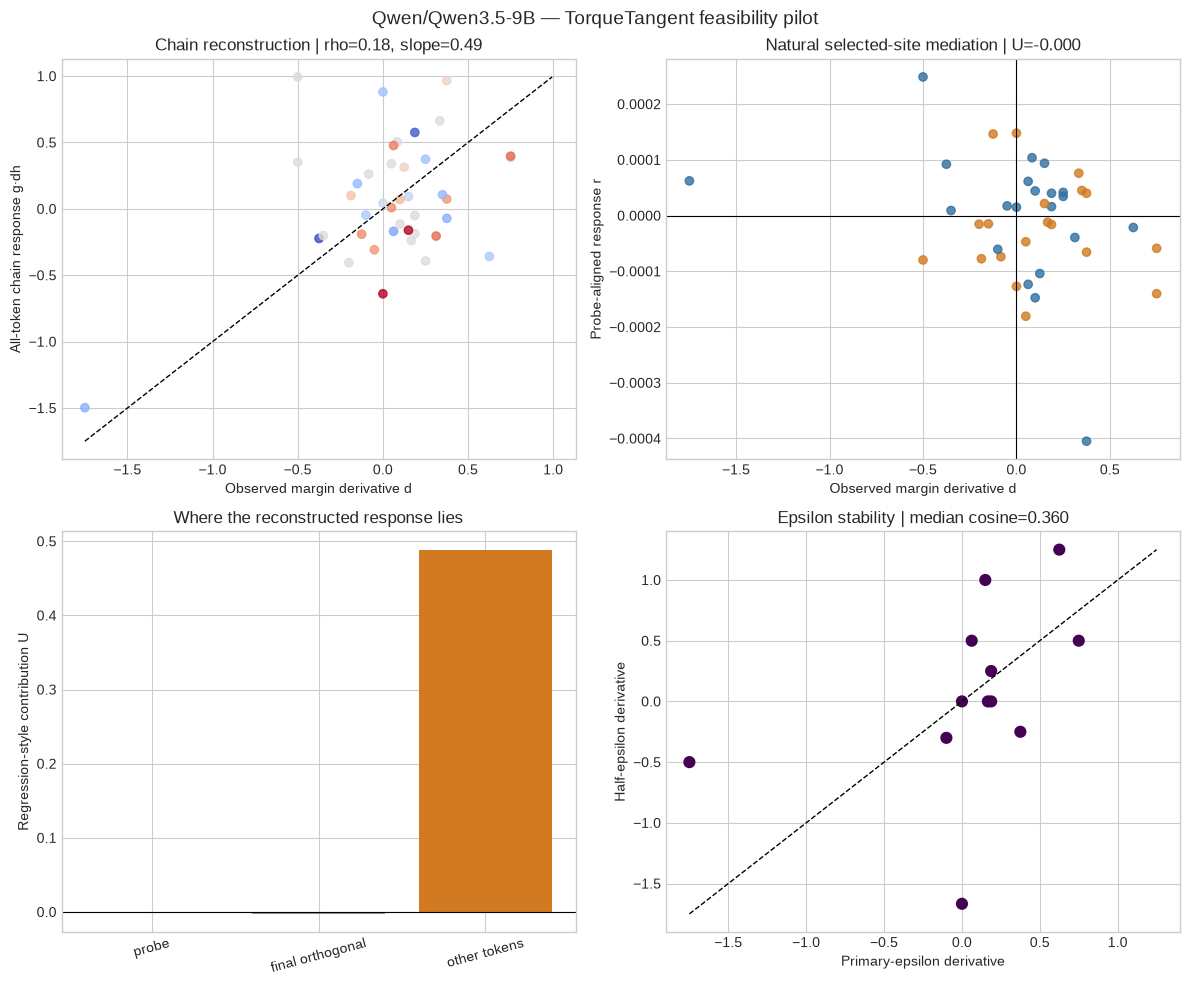

Saved: /content/drive/MyDrive/VisualTorque/results/Qwen__Qwen3.5-9B/torque_tangent_pilot_v1/analysis/torque_tangent_pilot.png


In [16]:
%%cell_progress 15/16 Plot reconstruction, mediation, and epsilon stability
cell_stage('Creating analysis figures')
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')
figure, axes = plt.subplots(2, 2, figsize=(12, 10))

axis = axes[0, 0]
axis.scatter(d, full, c=primary_frame['center_signed_torque'], cmap='coolwarm', alpha=0.8)
bounds = np.array([min(d.min(), full.min()), max(d.max(), full.max())])
axis.plot(bounds, bounds, '--', color='black', linewidth=1)
axis.set_xlabel('Observed margin derivative d')
axis.set_ylabel('All-token chain response g·dh')
axis.set_title(f'Chain reconstruction | rho={chain_spearman:.2f}, slope={chain_slope:.2f}')

axis = axes[0, 1]
colors = primary_frame['target_side'].map({'left': '#2f6f9f', 'right': '#d17a22'})
axis.scatter(d, probe_response, c=colors, alpha=0.8)
axis.axhline(0, color='black', linewidth=0.8)
axis.axvline(0, color='black', linewidth=0.8)
axis.set_xlabel('Observed margin derivative d')
axis.set_ylabel('Probe-aligned response r')
axis.set_title(f'Natural selected-site mediation | U={U_probe:.3f}')

axis = axes[1, 0]
contribution_labels = ['probe', 'final orthogonal', 'other tokens']
contribution_values = [U_probe, U_orth, U_other]
axis.bar(contribution_labels, contribution_values, color=['#2f6f9f', '#9a8f7a', '#d17a22'])
axis.axhline(0, color='black', linewidth=0.8)
axis.set_ylabel('Regression-style contribution U')
axis.set_title('Where the reconstructed response lies')
axis.tick_params(axis='x', rotation=15)

axis = axes[1, 1]
axis.scatter(
    stability_frame['primary_d'], stability_frame['half_d'],
    c=stability_frame['primary_vs_half_tangent_cosine'],
    cmap='viridis', vmin=0.9, vmax=1.0, s=60,
)
bounds = np.array([
    min(stability_frame['primary_d'].min(), stability_frame['half_d'].min()),
    max(stability_frame['primary_d'].max(), stability_frame['half_d'].max()),
])
axis.plot(bounds, bounds, '--', color='black', linewidth=1)
axis.set_xlabel('Primary-epsilon derivative')
axis.set_ylabel('Half-epsilon derivative')
axis.set_title(f'Epsilon stability | median cosine={median_stability_cosine:.3f}')

figure.suptitle(f'{MODEL_ID} — TorqueTangent feasibility pilot', fontsize=14)
figure.tight_layout()
figure_path = ANALYSIS_DIR / 'torque_tangent_pilot.png'
figure.savefig(figure_path, dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', figure_path)


In [17]:
%%cell_progress 16/16 Export the decision report and check cross-model status
cell_stage('Writing the pilot decision report')
if not chain_gate or not epsilon_gate:
    recommendation = (
        'Do not interpret U. Inspect per-path reconstruction, reduce epsilon or '
        'change the answer margin, then create a new versioned pilot.'
    )
elif not response_gate:
    recommendation = (
        'The model has too little local behavioral response on this path to estimate '
        'mediation reliably. Increase path coverage or use a more sensitive frozen '
        'margin before creating a new versioned pilot.'
    )
elif not probe_path_gate:
    recommendation = (
        'The global frozen probe does not track the local physical path reliably. '
        'Fit a scene-disjoint path-tangent probe on train/dev paths before asking '
        'whether that coordinate mediates probe-test behavior.'
    )
elif probe_mediation_supported:
    recommendation = (
        'Run the identical frozen pilot on Gemma in a fresh A100 runtime. If it '
        'replicates, preregister a 200-scene two-model study before scaling.'
    )
else:
    recommendation = (
        'The estimator is valid but the selected final-token probe component is not '
        'naturally mediating the response. Next test distributed token groups at one '
        'layer, then neighboring layers; do not retune activation-steering alpha.'
    )

decision_report = {
    'schema_version': 'torque-tangent-decision-1.0',
    'model_id': MODEL_ID,
    'status': status,
    'recommendation': recommendation,
    'artifacts': {
        'protocol': str(PROTOCOL_LOCK_PATH),
        'path_manifest': str(path_manifest_path),
        'primary_csv': str(ANALYSIS_DIR / 'pathwise_primary.csv'),
        'stability_csv': str(ANALYSIS_DIR / 'epsilon_stability.csv'),
        'sanity_summary': str(ANALYSIS_DIR / 'sanity_summary.json'),
        'mediation_summary': str(ANALYSIS_DIR / 'mediation_summary.json'),
        'resampling_nulls': str(ANALYSIS_DIR / 'resampling_nulls.npz'),
        'figure': str(ANALYSIS_DIR / 'torque_tangent_pilot.png'),
    },
}
write_json_atomic(ANALYSIS_DIR / 'decision_report.json', decision_report)
print('Decision:', status)
print('Next:', recommendation)

comparison_paths = {
    name: PROJECT_ROOT / 'results' / slug / 'torque_tangent_pilot_v1' /
    'analysis' / 'mediation_summary.json'
    for name, slug in {
        'Qwen/Qwen3.5-9B': 'Qwen__Qwen3.5-9B',
        'google/gemma-4-12B-it': 'google__gemma-4-12B-it',
    }.items()
}
if all(path.is_file() for path in comparison_paths.values()):
    rows = []
    for model_name, path in comparison_paths.items():
        summary = json.loads(path.read_text(encoding='utf-8'))
        rows.append({
            'model_id': model_name,
            'gates_passed': summary['sanity_gates']['mediation_interpretable'],
            'U_probe': summary['primary']['U_probe_aligned_final_token'],
            'U_ci_low': summary['primary']['U_probe_bootstrap_ci95'][0],
            'U_ci_high': summary['primary']['U_probe_bootstrap_ci95'][1],
            'permutation_p_positive': summary['mechanism_null'][
                'p_positive_add_one'
            ],
            'status': summary['status'],
        })
    comparison = pd.DataFrame(rows)
    comparison_root = PROJECT_ROOT / 'results' / 'torque_tangent_comparison_v1'
    comparison_root.mkdir(parents=True, exist_ok=True)
    comparison.to_csv(comparison_root / 'pilot_model_comparison.csv', index=False)
    display(comparison)
    print('Cross-model comparison:', comparison_root)
else:
    missing = [
        name for name, path in comparison_paths.items() if not path.is_file()
    ]
    print('Cross-model comparison deferred. Missing:', missing)


Export the decision report and check cross-model status:  94%|#########3| 15/16 [00:00<?, ?cell/s]

Decision: estimator_not_validated_do_not_interpret_mediation
Next: Do not interpret U. Inspect per-path reconstruction, reduce epsilon or change the answer margin, then create a new versioned pilot.
Cross-model comparison deferred. Missing: ['google/gemma-4-12B-it']
